In [1]:
import sys
import os
sys.path.append(os.path.abspath("src"))

In [2]:
import random, numpy as np, torch
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [3]:
print('seed test:', torch.rand(1).item(), np.random.rand())

seed test: 0.8822692632675171 0.3745401188473625


In [4]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from arc.Binary_Architecture import Model
import os
from data.Data_Interface import DataInterface
from model.Model_Interface import ModelInterface
from cf.DiPACE import DiPACE
from cf.DiPACE_Plus import DiPACE_Plus
from cf.GradCFA import DiPACE_FA
from eval.Evaluation import Evaluate
pd.set_option('display.max_columns', None)

In [5]:
df = pd.read_csv('datasets/credit.csv')
df = df.drop(columns='ZipCode')

In [6]:
print(df.shape)

(690, 15)


In [7]:
encoder = LabelEncoder()
df['Industry'] = encoder.fit_transform(df['Industry'])
label_mapping = dict(zip(encoder.classes_, range(len(encoder.classes_))))
print(label_mapping)
df['Ethnicity'] = encoder.fit_transform(df['Ethnicity'])
label_mapping = dict(zip(encoder.classes_, range(len(encoder.classes_))))
print(label_mapping)
df['Citizen'] = encoder.fit_transform(df['Citizen'])
label_mapping = dict(zip(encoder.classes_, range(len(encoder.classes_))))
print(label_mapping)

{'CommunicationServices': 0, 'ConsumerDiscretionary': 1, 'ConsumerStaples': 2, 'Education': 3, 'Energy': 4, 'Financials': 5, 'Healthcare': 6, 'Industrials': 7, 'InformationTechnology': 8, 'Materials': 9, 'Real Estate': 10, 'Research': 11, 'Transport': 12, 'Utilities': 13}
{'Asian': 0, 'Black': 1, 'Latino': 2, 'Other': 3, 'White': 4}
{'ByBirth': 0, 'ByOtherMeans': 1, 'Temporary': 2}


In [8]:
X = df.drop(columns=['Approved'])
y = df['Approved']

In [9]:
X = pd.get_dummies(X, columns=['Gender', 'Married', 'BankCustomer', 'Industry', 'Ethnicity', 'PriorDefault', 'CreditScore', 'Employed', 'DriversLicense', 'Citizen'])

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_scaled = scaler.transform(X)

In [12]:
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

In [13]:
input_size = X_train.shape[1]
model = Model(input_size)

In [14]:
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [15]:
print('weights checksum:', sum(p.sum().item() for p in model.parameters()))

weights checksum: 0.2995562255382538


In [16]:
epochs = 100
for epoch in range(epochs):
    optimizer.zero_grad()
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    optimizer.step()
    
    if (epoch+1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item()}')

Epoch [10/100], Loss: 0.6269097328186035
Epoch [20/100], Loss: 0.5406067371368408
Epoch [30/100], Loss: 0.43789467215538025
Epoch [40/100], Loss: 0.3481309413909912
Epoch [50/100], Loss: 0.28542473912239075
Epoch [60/100], Loss: 0.2432221621274948
Epoch [70/100], Loss: 0.21342213451862335
Epoch [80/100], Loss: 0.18987402319908142
Epoch [90/100], Loss: 0.16987968981266022
Epoch [100/100], Loss: 0.15236812829971313


In [17]:
with torch.no_grad():
    model.eval()
    outputs = model(X_test_tensor)
    predicted = (outputs >= 0.5).float()
    accuracy = (predicted == y_test_tensor).sum().item() / y_test.shape[0]
    print(f'Test Accuracy: {accuracy}')

Test Accuracy: 0.8260869565217391


In [18]:
model_path = 'pytorch_model.pth'
torch.save(model.state_dict(), model_path)

In [19]:
d = DataInterface(dataframe=df, target='Approved', continuous_features=['Age', 'Debt', 'YearsEmployed', 'Income'])
m = ModelInterface(model_path='pytorch_model.pth', input_size = input_size)

In [20]:
df = df[df['Approved']==0]
query_index = 10
query_instance = df.iloc[query_index].drop('Approved').to_list()
query_list = list(query_instance)   # the original list; later cells never overwrite it
print(query_index)

10


Desired class: tensor([1.], grad_fn=<RsubBackward1>)
Original class tensor([0.], grad_fn=<RoundBackward0>)
All CFs are classified as the desired class.
Query instance:          Age  Debt  YearsEmployed  Income  Gender  Married  BankCustomer  \
0  49.580002  19.0            0.0     0.0       1        1             1   

   Industry  Ethnicity  PriorDefault  Employed  CreditScore  DriversLicense  \
0         6          2             1         1            1               0   

   Citizen  outcome  
0        0      0.0  
CF instances:          Age  Debt  YearsEmployed  Income  Gender  Married  BankCustomer  \
0  35.189999   4.6           5.50     0.0       0        1             1   
1  52.330002   1.4           9.46     0.0       1        0             0   
2  25.180000  10.0           1.75     0.0       0        1             1   
3  31.250000   1.1           0.00     0.0       1        1             1   
4  20.670000   0.8           0.59     0.0       0        1             1   

   In

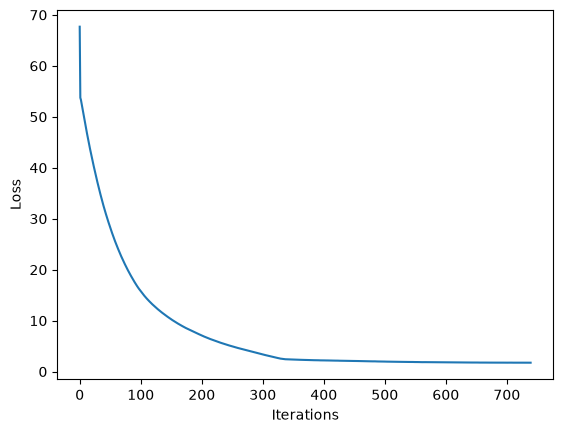

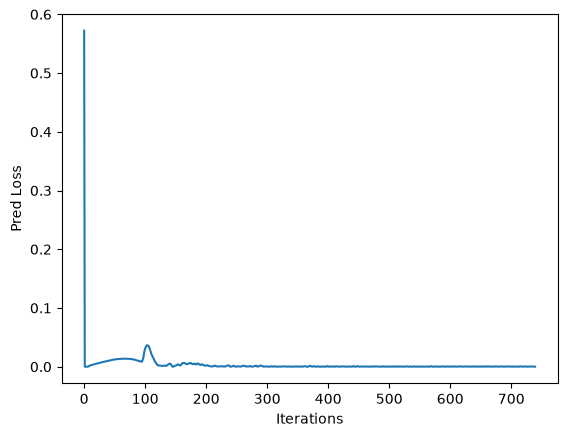

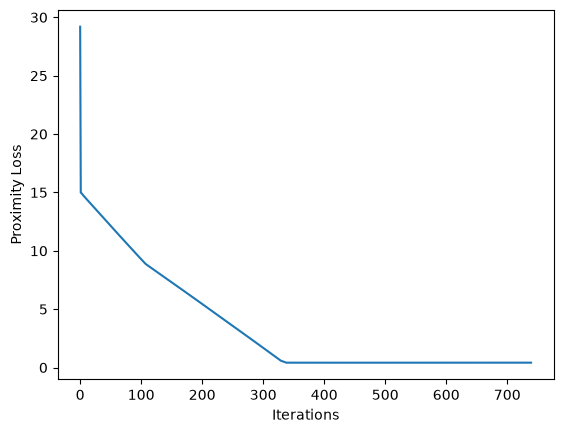

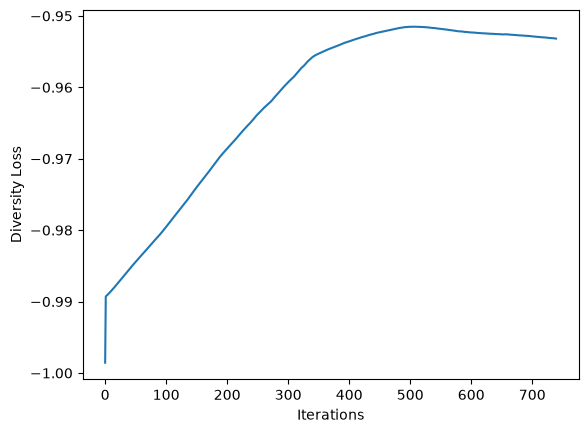

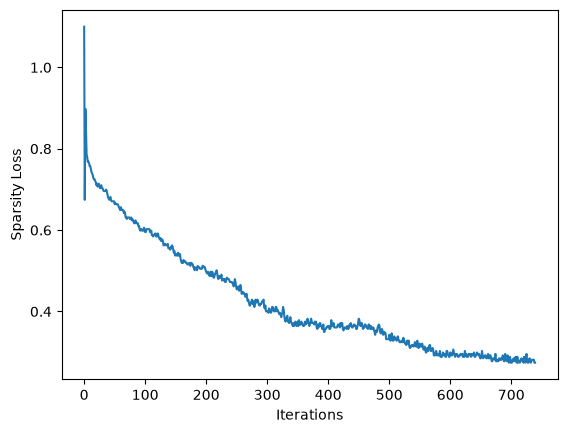

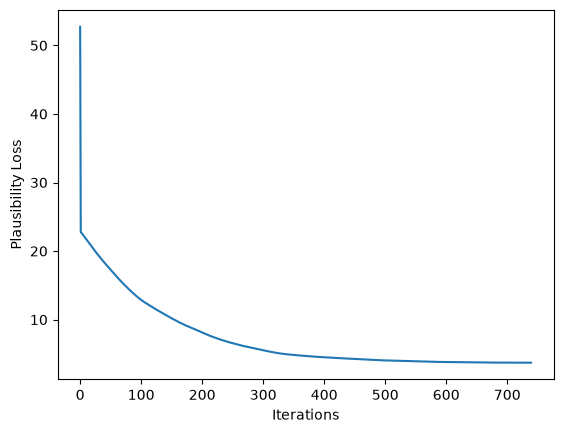

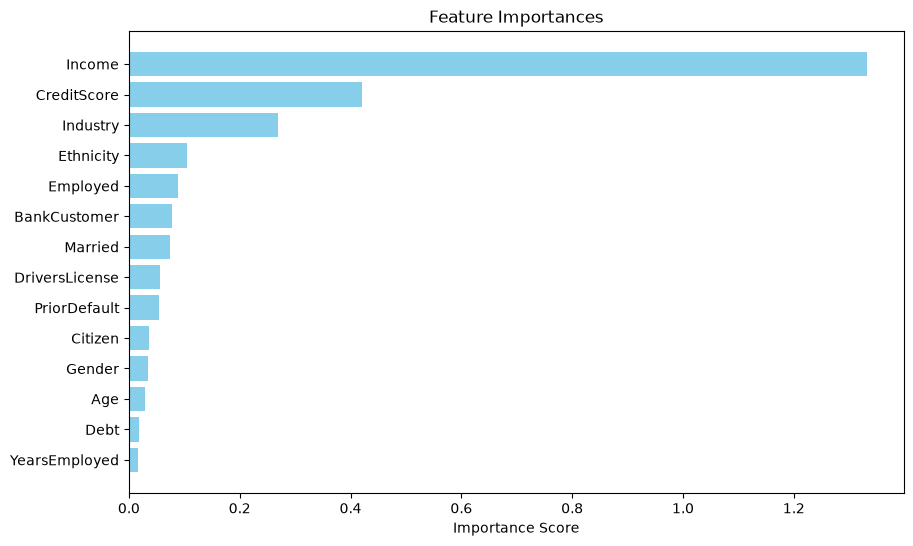

[('Income', np.float64(1.3320213556289673)), ('CreditScore', np.float64(0.4198718550412551)), ('Industry', np.float64(0.26829667389392853)), ('Ethnicity', np.float64(0.10525284819304943)), ('Employed', np.float64(0.08884423598647118)), ('BankCustomer', np.float64(0.0782863236963749)), ('Married', np.float64(0.07435277849435806)), ('DriversLicense', np.float64(0.05687645077705383)), ('PriorDefault', np.float64(0.054472715593874454)), ('Citizen', np.float64(0.036620695143938065)), ('Gender', np.float64(0.03370023937895894)), ('Age', np.float64(0.029565254226326942)), ('Debt', np.float64(0.01889580860733986)), ('YearsEmployed', np.float64(0.016096947714686394))]


In [21]:
# GradCFA (DiPACE_FA), Config A: the paper's Credit Approval hyperparameters
from cf.GradCFA import DiPACE_FA

torch.manual_seed(SEED); np.random.seed(SEED)
exp_fa = DiPACE_FA(d, m)
cf_a = exp_fa.generate_counterfactuals(
    query_list, total_CFs=5,
    proximity_weight=0.5, sparsity_weight=0.5, plausibility_weight=0.5, diversity_weight=0.5,
    penalty_scale=0.1, perturb_scale=0.5,
    proximity_threshold=0.2, sparsity_threshold=0.2,
    plausibility_threshold=0.4, diversity_threshold=0.9,
    high_loss_threshold=0.5, loss_converge_maxiter=2)
ranking_a = exp_fa.importance_ranking
print(ranking_a)

Desired class: tensor([1.], grad_fn=<RsubBackward1>)
Original class tensor([0.], grad_fn=<RoundBackward0>)
All CFs are classified as the desired class.
Final Loss: tensor(1.7079, grad_fn=<SubBackward0>)
Final Pred Loss: tensor(0., grad_fn=<MeanBackward0>)
Final Proximity Loss: tensor(0.3800, grad_fn=<MeanBackward0>)
Final Diversity Loss: tensor(0.9538, grad_fn=<LinalgDetBackward0>)
Final Sparsity Loss: tensor(0.2525)
Final Plausibility Loss: tensor(3.7010, grad_fn=<AddBackward0>)
Unacceptably high loss. Perturbing relevant features.
All CFs are classified as the desired class.
Final Loss: tensor(1.3652, grad_fn=<SubBackward0>)
Final Pred Loss: tensor(0.0006, grad_fn=<MeanBackward0>)
Final Proximity Loss: tensor(0.3663, grad_fn=<MeanBackward0>)
Final Diversity Loss: tensor(0.9517, grad_fn=<LinalgDetBackward0>)
Final Sparsity Loss: tensor(0.2557)
Final Plausibility Loss: tensor(3.0371, grad_fn=<AddBackward0>)
Unacceptably high loss. Perturbing relevant features.
All CFs are classified as

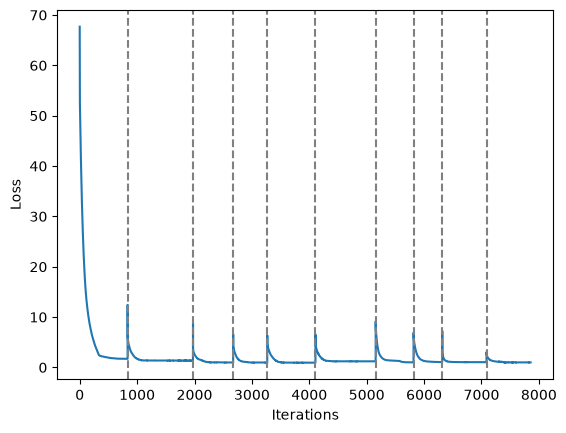

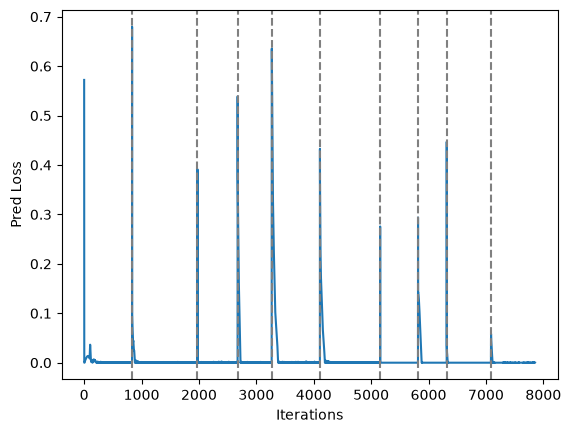

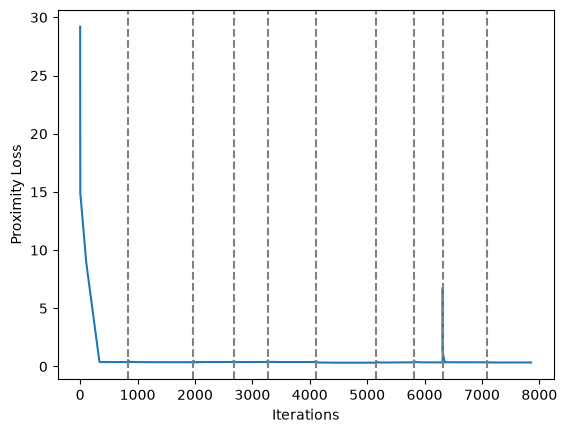

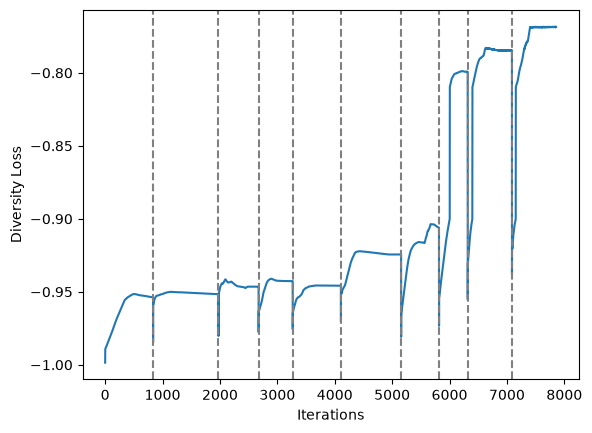

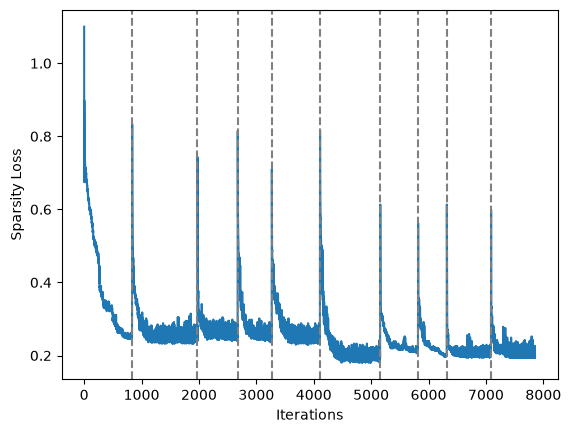

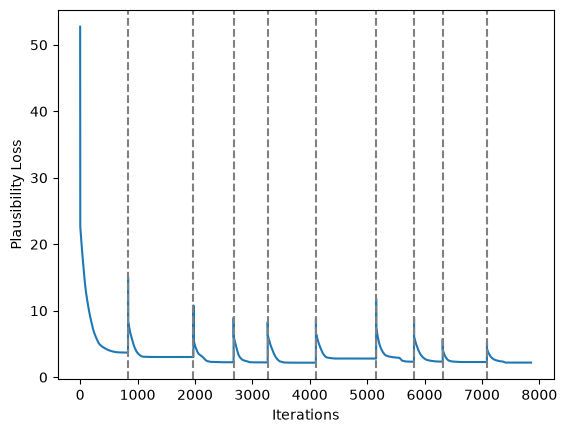

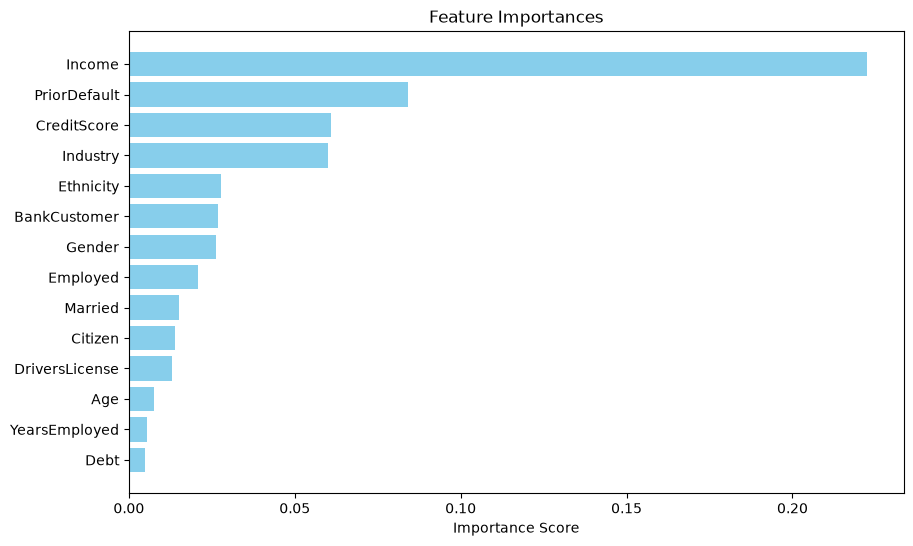

[('Income', np.float64(0.22244875133037567)), ('PriorDefault', np.float64(0.08426778391003609)), ('CreditScore', np.float64(0.06101568172807279)), ('Industry', np.float64(0.060035482581172674)), ('Ethnicity', np.float64(0.027878376841545104)), ('BankCustomer', np.float64(0.026823380030691624)), ('Gender', np.float64(0.026197410188615322)), ('Employed', np.float64(0.020962893031537533)), ('Married', np.float64(0.015224653296172619)), ('Citizen', np.float64(0.01402661701043447)), ('DriversLicense', np.float64(0.0130370301194489)), ('Age', np.float64(0.007482126820832491)), ('YearsEmployed', np.float64(0.005469096824526787)), ('Debt', np.float64(0.0047522434033453465))]


In [22]:
# GradCFA (DiPACE_FA), Config B: repo default settings, as in the authors' notebook
torch.manual_seed(SEED); np.random.seed(SEED)
exp_fa_b = DiPACE_FA(d, m)
cf_b = exp_fa_b.generate_counterfactuals(query_list, total_CFs=5, high_loss_threshold=0.7)
ranking_b = exp_fa_b.importance_ranking
print(ranking_b)

Desired class: tensor([1.], grad_fn=<RsubBackward1>)
Original class tensor([0.], grad_fn=<RoundBackward0>)
All CFs are classified as the desired class.
Final Loss: tensor(1.0306, grad_fn=<SubBackward0>)
Final Pred Loss: tensor(0., grad_fn=<MeanBackward0>)
Final Proximity Loss: tensor(0.3555, grad_fn=<MeanBackward0>)
Final Diversity Loss: tensor(0.9598, grad_fn=<LinalgDetBackward0>)
Final Sparsity Loss: tensor(0.2492)
Final Plausibility Loss: tensor(2.8818, grad_fn=<MeanBackward0>)
Unacceptably high loss. Perturbing relevant features.
All CFs are classified as the desired class.
Final Loss: tensor(0.9485, grad_fn=<SubBackward0>)
Final Pred Loss: tensor(0., grad_fn=<MeanBackward0>)
Final Proximity Loss: tensor(0.3562, grad_fn=<MeanBackward0>)
Final Diversity Loss: tensor(0.9557, grad_fn=<LinalgDetBackward0>)
Final Sparsity Loss: tensor(0.2361)
Final Plausibility Loss: tensor(2.7096, grad_fn=<MeanBackward0>)
Unacceptably high loss. Perturbing relevant features.
All CFs are classified as t

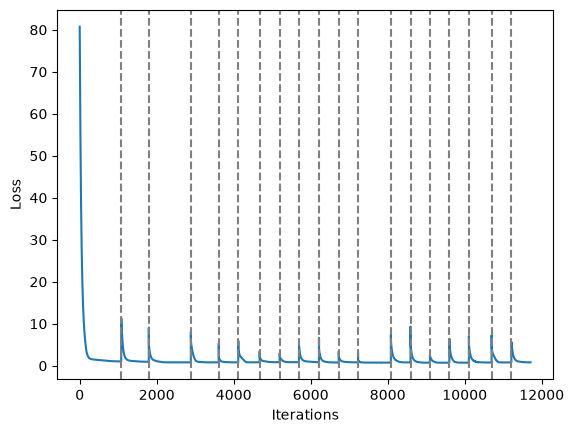

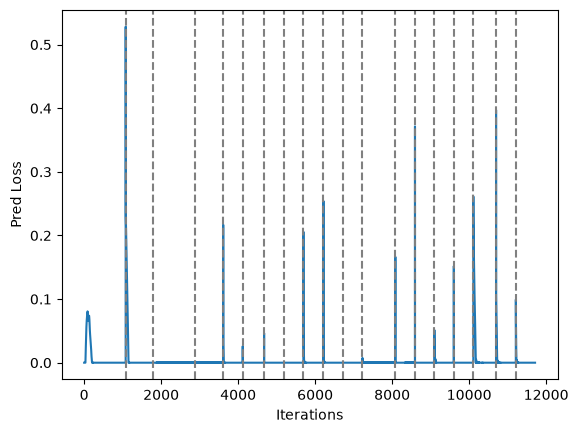

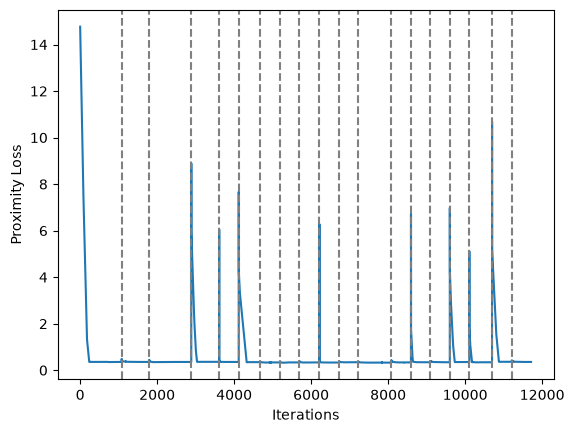

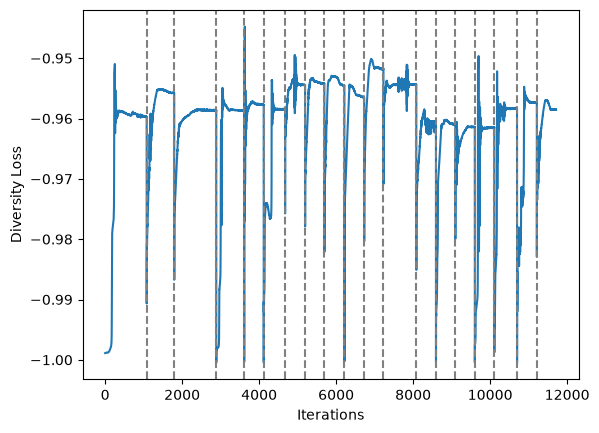

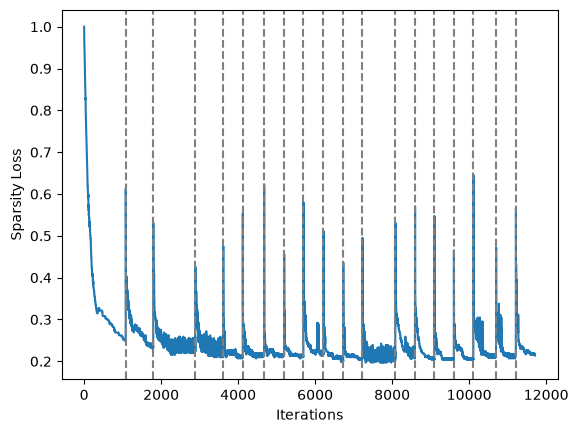

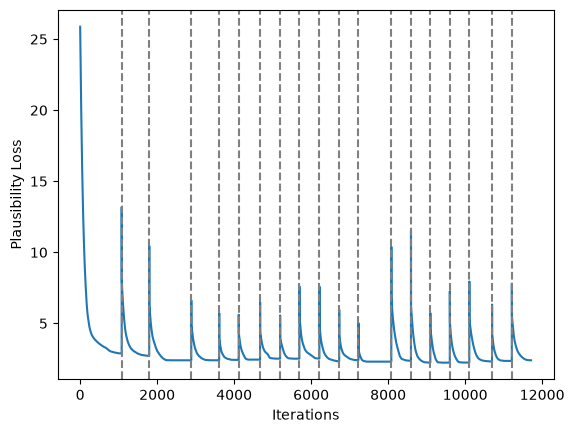

In [23]:
# DiPACE baseline (the authors' earlier method), same query
torch.manual_seed(SEED); np.random.seed(SEED)
exp = DiPACE(d, m)
cf_dipace = exp.generate_counterfactuals(query_list, total_CFs=5, high_loss_threshold=0.7)

In [24]:
# Evaluate all three on the same query (one query only: NOT a result, just a pipeline check)
ev = Evaluate(d, m)
rows = {}
for name, out in [('GradCFA A (paper settings)', cf_a),
                  ('GradCFA B (repo defaults)', cf_b),
                  ('DiPACE (baseline)', cf_dipace)]:
    q, c = out
    q = torch.Tensor(q).float()
    c = torch.Tensor(c).float()
    rows[name] = {
        'Proximity': ev.evaluate_proximity(q, c).item(),
        'Sparsity': ev.evaluate_sparsity(q, c).item(),
        'Diversity': ev.evaluate_diversity(c).item(),
        'Plausibility (raw)': ev.evaluate_plausibility(c, d.norm_encoded_features, k=1).item(),
        'Confidence': ev.evaluate_confidence(c, desired_class=1).item(),
    }
pd.DataFrame(rows).T.round(4)

,Proximity,Sparsity,Diversity,Plausibility (raw),Confidence
GradCFA A (paper settings),0.2563,0.2098,0.9549,2.6318,0.6931
GradCFA B (repo defaults),0.2206,0.1738,0.8582,1.4146,0.7588
DiPACE (baseline),0.2227,0.1902,0.8709,1.3279,0.8439
